# Project 3: Earnings surprises and stock reactions, two industries compared
**Client:** JPMorgan Chase & Co. (Depository Institutions, SIC 60) | **Benchmarked Against:** Electronic Equipment (SIC 36)

___________________________________________________________________________________________________________________


# Setup: libraries and settings
**Sources:** Class materials + Professor Advice

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide a harmless pandas warning

import pandas as pd
import wrds

conn = wrds.Connection()    # log in to WRDS (type your username and password if asked)

# Settings. If you want to change something, change it here only.
SIC        = "60"            
FY_START   = "2021-01-01"     # we study fiscal years that END between FY_START and FY_END
FY_END     = "2024-12-31"
PULL_START = "2019-06-01"     # we pull earlier years too, because the EPS change needs last year's EPS and price
RET_START  = "2020-12-01"     # first month of returns (12 months before the first fiscal year-end)
RET_END    = "2025-01-31"     # last month of returns
MIN_PRC    = 5                # rule: drop a company-year if last year's price is below this
MAX_CHG    = 1                # rule: drop a company-year if the EPS change is bigger than this (up or down)

Loading library list...
Done


# _________________________________________________________________________________________________________________

#   Step 1:



In [2]:
# Step 1. Read the link file
# In-class 10 & Assignment 8

# 1a. Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# 1b. gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())
link.head()

link rows: 309 | companies: 299


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,002001,16505,1973-01-31,1990-12-31,60,BPOP,POPULAR INC
1,002002,16505,1991-01-02,2099-12-31,60,BPOP,POPULAR INC
2,002005,16548,1972-12-14,2099-12-31,60,BOH,BANK OF HAWAII CORP
3,002019,49656,1969-12-04,2099-12-31,60,BK,BANK OF NEW YORK MELLON CORP
4,002968,47896,1969-03-05,2099-12-31,60,JPM,JPMORGAN CHASE & CO


# _________________________________________________________________________________________________________________

#   Step 2:

In [3]:
# Step 2. Pull the annual data
# Assignement 8 + fundq changes (AI help to don't make mistakes)
# 2a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.

fq = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
fq["epspxq"]  = fq["epspxq"].astype("float64")
fq["prccq"] = fq["prccq"].astype("float64")

# 2d. Check what we got.
print("company-years pulled from Compustat:", len(fq))
fq.head()

company-years pulled from Compustat: 6172


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,002002,2019-06-30,2019,2,2019-07-24,1.77,54.24
1,002005,2019-06-30,2019,2,2019-07-22,1.40,82.91
2,002019,2019-06-30,2019,2,2019-07-17,1.01,44.15
3,002968,2019-06-30,2019,2,2019-07-16,2.83,111.80
4,003231,2019-06-30,2019,2,2019-07-17,1.95,72.64


In [4]:
fq.info() #check

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6172 entries, 0 to 6171
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   gvkey     6172 non-null   string        
 1   datadate  6172 non-null   datetime64[ns]
 2   fyearq    6172 non-null   Int64         
 3   fqtr      6172 non-null   Int64         
 4   rdq       6121 non-null   datetime64[ns]
 5   epspxq    6113 non-null   float64       
 6   prccq     6144 non-null   float64       
dtypes: Int64(2), datetime64[ns](2), float64(2), string(1)
memory usage: 349.7 KB


# _________________________________________________________________________________________________________________

#   Step 3:

In [5]:
# Step 3a. Merge 1: add permno from the link file
# In-class 11 & Assignment 8
panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel))


3a. after the merge (a gvkey with 2 links is now on 2 rows): 6387


In [6]:
# Step 3b. Keep only the link that was valid on the fiscal quarter end date
# In-class 11 & Assignment 8 + AI to check datadate change
# True/False for each row: the date is between the start and the end of the link.
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
panel = panel[valid]

# How many rows share the same gvkey + datadate with another row?
n_dup = panel.duplicated(["gvkey", "datadate"]).sum()
print("3b. rows that repeat a gvkey + datadate before we drop them:", n_dup)

# If one company-year still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "datadate"])

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
r1, c1 = len(fq), fq["gvkey"].nunique()          # before the link
r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link
print("3b. company-years after the link merge:", r2)

3b. rows that repeat a gvkey + datadate before we drop them: 0
3b. company-years after the link merge: 6137


In [7]:
# Check: does any key (gvkey + datadate) appear more than once?
# In-class 11 & Assignment 8
# duplicated() marks a row True if an earlier row has the same gvkey and fyear. sum() counts the True values.
print("duplicate keys:", panel.duplicated(["gvkey", "datadate"]).sum(), "(it must be 0)")

duplicate keys: 0 (it must be 0)


In [8]:
# Step 3c. Merge 2: Add lagged EPS (-4 quarters) and price (-1 quarter), and compute SUE 
# In-class 10 & Assignment 8; AI assistance

# 1. Prior cleanup: drop columns if they already exist from a previous run
cols_to_drop = ["qtr_num", "prc_lag1", "eps_lag4", "sue"]
panel = panel.drop(columns=[c for c in cols_to_drop if c in panel.columns])

# 2. Create a sequential time identifier for quarterly data (fiscal year × 4 + fiscal quarter)
panel['qtr_num'] = panel['fyearq'] * 4 + panel['fqtr']

# 3. Table for lagged PRICE: shift forward by +1 quarter to match last quarter's price
last_prc = panel[["gvkey", "qtr_num", "prccq"]].copy()
last_prc["qtr_num"] = last_prc["qtr_num"] + 1
last_prc = last_prc.rename(columns={"prccq": "prc_lag1"})

# 4. Table for lagged EPS: shift forward by +4 quarters to match the same quarter last year
last_eps = panel[["gvkey", "qtr_num", "epspxq"]].copy()
last_eps["qtr_num"] = last_eps["qtr_num"] + 4
last_eps = last_eps.rename(columns={"epspxq": "eps_lag4"})

# 5. Merge the lagged values back into the main panel using left joins
panel = panel.merge(last_prc, on=["gvkey", "qtr_num"], how="left")
panel = panel.merge(last_eps, on=["gvkey", "qtr_num"], how="left")

# 6. Calculate Standardized Unexpected Earnings (SUE): (current EPS - EPS 4 quarters ago) / last quarter's price
panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

# 7. Check the resulting panel sample
panel[["gvkey", "fyearq", "fqtr", "epspxq", "eps_lag4", "prc_lag1", "sue"]].head(8)


,gvkey,fyearq,fqtr,epspxq,eps_lag4,prc_lag1,sue
0,002002,2019,2,1.77,NaN,NaN,NaN
1,002005,2019,2,1.40,NaN,NaN,NaN
2,002019,2019,2,1.01,NaN,NaN,NaN
3,002968,2019,2,2.83,NaN,NaN,NaN
4,003231,2019,2,1.95,NaN,NaN,NaN
5,003243,2019,2,1.94,NaN,NaN,NaN
6,004674,2019,2,0.37,NaN,NaN,NaN
7,004690,2019,2,10.56,NaN,NaN,NaN


In [9]:
# Display a complete row with the lagged variables for a specific company
# AI help
sample_check = panel.dropna(subset=["sue"]).head(1)
print(sample_check[["gvkey", "fyearq", "fqtr", "qtr_num", "epspxq", "eps_lag4", "prc_lag1", "sue"]])

       gvkey  fyearq  fqtr  qtr_num  epspxq  eps_lag4  prc_lag1    sue
1148  002002    2020     2     8082    1.49      1.77      35.0 -0.008


In [10]:
# Check n°2 you told me to do during our meeting, verify that eps_lag4 and prc_lag1 are correct
# AI help to discuss about what you told me during the meeting and try to find what you wanted me to understand
panel[panel["gvkey"] == "002002"][["fyearq", "fqtr", "qtr_num", "epspxq", "eps_lag4", "prccq", "prc_lag1", "sue"]]

,fyearq,fqtr,qtr_num,epspxq,eps_lag4,prccq,prc_lag1,sue
0,2019,2,8078,1.77,NaN,54.24,NaN,NaN
286,2019,3,8079,1.71,NaN,54.08,54.24,NaN
572,2019,4,8080,1.72,NaN,58.75,54.08,NaN
860,2020,1,8081,0.37,NaN,35.00,58.75,NaN
1148,2020,2,8082,1.49,1.77,37.17,35.00,-0.008000
1436,2020,3,8083,2.01,1.71,36.27,37.17,0.008071
1724,2020,4,8084,2.10,1.72,56.32,36.27,0.010477
2012,2021,1,8085,3.13,0.37,70.32,56.32,0.049006
2298,2021,2,8086,2.67,1.49,75.05,70.32,0.016780
2582,2021,3,8087,3.09,2.01,77.67,75.05,0.014390


In [11]:
# Apply Rules to Filter the Sample
# Assignment 8, AI to go from the assignment example to the fundq we need
events = panel.copy()
print(len(events))
# Rule 1: Drop rows where announcement date (rdq) is missing
events = events[events["rdq"].notna()]
print("Rows with a known rdq:", len(events))

# Rule 2: Keep only announcements between January 2021 and December 2024 (based on rdq)
events = events[(events["rdq"] >= "2021-01-01") & (events["rdq"] <= "2024-12-31")]
print("Rows where rdq is between 2021 and 2024:", len(events))

# Rule 3 Drop rows where SUE could not be computed
events = events[events["sue"].notna()].copy()
print("Rows with a valid SUE:", len(events))

# Rule 4: Last quarter's price must be at least $5
events = events[events["prc_lag1"] >= MIN_PRC]
print("Rows where previous price >= $5:", len(events))

# Rule 5: The absolute value of SUE must be 1 or less
events = events[events["sue"].abs() <= MAX_CHG].reset_index(drop=True)
print("Rows where |SUE| <= 1:", len(events))
      
print(len(events))

6137
Rows with a known rdq: 6092
Rows where rdq is between 2021 and 2024: 4144
Rows with a valid SUE: 4125
Rows where previous price >= $5: 3990
Rows where |SUE| <= 1: 3990
3990


# _________________________________________________________________________________________________________________

#   Step 4:

In [12]:
# ===== Step 4. Pull Daily Stock and Market Returns & CAR 
# Every line from In-class 11 and some AI assistance to check if everything ok

# 1. Get the unique list of permnos from our filtered events table
permnos = ",".join(events["permno"].astype(str).unique())

# 2. Pull daily stock returns (crsp.dsf)
stock = conn.raw_sql(f"""
    select permno, date, ret 
    from crsp.dsf
    where permno in ({permnos}) 
    and date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# 3. Pull daily market index returns (crsp.dsi)
mkt = conn.raw_sql(f"""
    select date, vwretd 
    from crsp.dsi
    where date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# 4. Clean data types
stock["permno"] = stock["permno"].astype(int)
stock["ret"] = pd.to_numeric(stock["ret"], errors="coerce").astype("float64")
mkt["vwretd"] = pd.to_numeric(mkt["vwretd"], errors="coerce").astype("float64")

# ----- Trading-day number (from In-class 11) -----
market_cal = mkt.sort_values("date").reset_index(drop=True)
market_cal["tday"] = market_cal.index + 1

# ----- Merge 3: market return and tday on every stock-day -----
daily = stock.merge(market_cal[["date", "vwretd", "tday"]], on="date", how="left")
daily["ar"] = daily["ret"] - daily["vwretd"]

# ----- Day 0 (from In-class 11) -----
events["event_id"] = events.index
pairs = events[["event_id", "rdq"]].merge(market_cal[["date", "tday"]], how="cross")
pairs = pairs[pairs["date"] >= pairs["rdq"]]
day0 = pairs.groupby("event_id")["tday"].min().reset_index()
day0 = day0.rename(columns={"tday": "day0"})
events = events.merge(day0, on="event_id", how="left")

# ----- Three days per announcement (safe version keeping gvkey and rdq for checks) -----
offsets = pd.DataFrame({"offset": [-1, 0, 1]})
window = events[["event_id", "gvkey", "permno", "rdq", "day0"]].merge(offsets, how="cross")
window["tday"] = window["day0"] + window["offset"]

# ----- Merge 4: the abnormal return of each of those days (from In-class 11) -----
window = window.merge(daily[["permno", "tday", "ar"]], on=["permno", "tday"], how="left")

# ----- CAR (from In-class 11) -----
car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
car = car.rename(columns={"sum": "car", "count": "days_found"})
car["car"] = car["car"].round(6)
events = events.merge(car, on="event_id", how="left")

In [13]:
# ===== Rule 6: Final Event Sample (all 3 days found) =====
final_table = events[events["days_found"] == 3].reset_index(drop=True)
print("Final Event Sample after Rule 6 (final_table):", len(final_table))

Final Event Sample after Rule 6 (final_table): 3964


In [14]:
# Check your answers: the dates of the trading-day numbers around each day 0
check = window.merge(market_cal[["tday", "date"]], on="tday", how="left")
check["weekday"] = check["date"].dt.day_name()
check[["gvkey", "permno", "rdq", "weekday", "offset", "tday", "date"]].head(12)

,gvkey,permno,rdq,weekday,offset,tday,date
0,002002,16505,2021-01-28,Wednesday,-1,39,2021-01-27
1,002002,16505,2021-01-28,Thursday,0,40,2021-01-28
2,002002,16505,2021-01-28,Friday,1,41,2021-01-29
3,002005,16548,2021-01-25,Friday,-1,36,2021-01-22
4,002005,16548,2021-01-25,Monday,0,37,2021-01-25
5,002005,16548,2021-01-25,Tuesday,1,38,2021-01-26
6,002019,49656,2021-01-20,Tuesday,-1,33,2021-01-19
7,002019,49656,2021-01-20,Wednesday,0,34,2021-01-20
8,002019,49656,2021-01-20,Thursday,1,35,2021-01-21
9,002968,47896,2021-01-15,Thursday,-1,31,2021-01-14


 # -------------The six checks-------------

In [15]:
# THE 6 DATA QUALITY CHECKS
# In-class Week 10; AI assistance
# --- CHECK 1: SAMPLE CONSTRUCTION FUNNEL ---
print("=== CHECK 1: SAMPLE CONSTRUCTION FUNNEL ===")

# 1. Compustat & CCM Link
print(f"1. Compustat quarterly data (fq): {len(fq)} rows, {fq['gvkey'].nunique()} firms")
print(f"2. After CCM Link merge: {len(panel)} rows, {panel['gvkey'].nunique()} firms")

# Rules 1 to 5 (applied sequentially on the event table)
ev_funnel = panel.copy()

r1_before = len(ev_funnel)
ev_funnel = ev_funnel[ev_funnel["rdq"].notna()]
print(f"   Rule 1 (rdq known) - Before: {r1_before} | After: {len(ev_funnel)} | Removed: {r1_before - len(ev_funnel)}")

r2_before = len(ev_funnel)
ev_funnel = ev_funnel[(ev_funnel["rdq"] >= "2021-01-01") & (ev_funnel["rdq"] <= "2024-12-31")]
print(f"   Rule 2 (rdq 2021-2024) - Before: {r2_before} | After: {len(ev_funnel)} | Removed: {r2_before - len(ev_funnel)}")

r3_before = len(ev_funnel)
ev_funnel = ev_funnel[ev_funnel["sue"].notna()]
print(f"   Rule 3 (SUE computable) - Before: {r3_before} | After: {len(ev_funnel)} | Removed: {r3_before - len(ev_funnel)}")

r4_before = len(ev_funnel)
ev_funnel = ev_funnel[ev_funnel["prc_lag1"] >= MIN_PRC]
print(f"   Rule 4 (Price >= $5) - Before: {r4_before} | After: {len(ev_funnel)} | Removed: {r4_before - len(ev_funnel)}")

r5_before = len(ev_funnel)
ev_funnel = ev_funnel[ev_funnel["sue"].abs() <= MAX_CHG].reset_index(drop=True)
print(f"   Rule 5 (|SUE| <= 1) - Before: {r5_before} | After: {len(ev_funnel)} | Removed: {r5_before - len(ev_funnel)}")
# At this point, ev_funnel has exactly 3990 rows (after Rule 5)

# --- Transition to Daily Stock Returns ---

# Merge 3 (Merging daily stock returns with market calendar to create 'daily')
m3_before = len(stock)
m3_after = len(daily)
print(f"   Merge 3 (Daily stock & market returns merge) - Before: {m3_before} | After: {m3_after} | Removed: {m3_before - m3_after}")

# Merge 4 (Merging abnormal returns 'ar' onto the 3-day event window)
# Right before Merge 4, the window table contains 3990 * 3 = 11970 rows (3 days per event)
m4_before = len(window) 
m4_after = len(window) # Left join preserves the window structure
print(f"   Merge 4 (Abnormal returns merge on event window) - Before: {m4_before} | After: {m4_after} | Removed: 0")

# Rule 6 (Final filter: keep only events that have all 3 valid trading days)
r6_before = len(events) # Number of valid events before CAR filter (3990)
r6_after = len(final_table) # Final sample size (3966)
print(f"   Rule 6 (All 3 daily returns found - FINAL) - Before: {r6_before} | After: {r6_after} | Removed: {r6_before - r6_after}")

=== CHECK 1: SAMPLE CONSTRUCTION FUNNEL ===
1. Compustat quarterly data (fq): 6172 rows, 291 firms
2. After CCM Link merge: 6137 rows, 290 firms
   Rule 1 (rdq known) - Before: 6137 | After: 6092 | Removed: 45
   Rule 2 (rdq 2021-2024) - Before: 6092 | After: 4144 | Removed: 1948
   Rule 3 (SUE computable) - Before: 4144 | After: 4125 | Removed: 19
   Rule 4 (Price >= $5) - Before: 4125 | After: 3990 | Removed: 135
   Rule 5 (|SUE| <= 1) - Before: 3990 | After: 3990 | Removed: 0
   Merge 3 (Daily stock & market returns merge) - Before: 262575 | After: 262575 | Removed: 0
   Merge 4 (Abnormal returns merge on event window) - Before: 11970 | After: 11970 | Removed: 0
   Rule 6 (All 3 daily returns found - FINAL) - Before: 3990 | After: 3964 | Removed: 26


In [16]:
# --- CHECK 2: Duplicates ---
print("\n=== CHECK 2: DUPLICATES ===")
dups = final_table.duplicated(["gvkey", "rdq"]).sum()
print(f"Number of duplicate (gvkey, rdq) pairs in final_table: {dups} (Must be 0)")


=== CHECK 2: DUPLICATES ===
Number of duplicate (gvkey, rdq) pairs in final_table: 0 (Must be 0)


In [17]:
# --- CHECK 3: Dates ---
print("\n=== CHECK 3: DATES ===")
# (a) Announcement date must be later than the quarter end date
bad_dates = (final_table["rdq"] <= final_table["datadate"]).sum()
print(f"(a) Announcements on or before quarter-end (should be 0): {bad_dates}")

# (b) Day 0 must be a valid trading day in market_cal
valid_day0 = final_table["day0"].isin(market_cal["tday"]).all()
print(f"(b) Every day0 is a valid trading day in market_cal: {valid_day0}")


=== CHECK 3: DATES ===
(a) Announcements on or before quarter-end (should be 0): 0
(b) Every day0 is a valid trading day in market_cal: True


In [18]:
# --- CHECK 4: 5 Largest CARs ---
print("\n=== CHECK 4: 5 LARGEST |CAR| ===")
cols_car = ["ticker", "datadate", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "car"]
top5_car = final_table.loc[final_table["car"].abs().nlargest(5).index, cols_car]
print(top5_car)


=== CHECK 4: 5 LARGEST |CAR| ===
     ticker   datadate        rdq  epspxq  eps_lag4  prc_lag1       sue  \
3163    FLG 2023-12-31 2024-01-31   -3.76      0.30     11.34 -0.358025   
1736     SI 2022-06-30 2022-07-19    1.14      0.81    150.57  0.002192   
2981   BRBS 2023-09-30 2023-10-31   -2.18      0.15      8.85 -0.263277   
1898   SIVB 2022-09-30 2022-10-20    7.26      6.33    394.99  0.002354   
2368    FRC 2023-03-31 2023-04-24    1.24      2.03    121.89 -0.006481   

           car  
3163 -0.488948  
1736  0.413605  
2981 -0.347881  
1898 -0.330530  
2368 -0.328651  


# _________________________________________________________________________________________________________________

#   Step 5 & 6:

In [19]:
# ===== Step 5 & 6: Client Firm (JPM) Spot Check & Manual Rebuild =====
print("\n=== CHECK 5 & 6: CLIENT FIRM (JPM) SPOT CHECK ===")
jpm_subset = final_table[final_table["ticker"] == "JPM"]

if len(jpm_subset) > 0:
    # Select the first available announcement for JPM
    jpm_row = jpm_subset.iloc[0]
    print("Notebook row for JPM:")
    print(jpm_row[["ticker", "gvkey", "permno", "datadate", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "event_id", "day0", "car"]])

    # Retrieve the 3 daily returns for Check 6 manual calculation (SANS 'ar' car window l'a déjà)
    jpm_days = window[window["event_id"] == jpm_row["event_id"]].merge(
        daily[["permno", "tday", "date", "ret", "vwretd"]], 
        on=["permno", "tday"], 
        how="left"
    )
    print("\nDaily returns breakdown for JPM (Days -1, 0, +1):")
    print(jpm_days[["date", "tday", "ret", "vwretd", "ar"]])
else:
    print("JPM is not present in final_table. Please select an alternative client firm.")


=== CHECK 5 & 6: CLIENT FIRM (JPM) SPOT CHECK ===
Notebook row for JPM:
ticker                      JPM
gvkey                    002968
permno                    47896
datadate    2020-12-31 00:00:00
rdq         2021-01-15 00:00:00
epspxq                      3.8
eps_lag4                   2.58
prc_lag1                  96.27
sue                    0.012673
event_id                      3
day0                         32
car                   -0.016356
Name: 3, dtype: object

Daily returns breakdown for JPM (Days -1, 0, +1):
        date  tday       ret    vwretd        ar
0 2021-01-14    31  0.005842 -0.000047  0.005889
1 2021-01-15    32 -0.017922 -0.008542 -0.009380
2 2021-01-19    33 -0.004328  0.008537 -0.012865


In [20]:
#=== Final Result ===

In [21]:
final_table["sue_group"] = pd.qcut(final_table["sue"].rank(method="first"), 3, labels=["Low", "Middle", "High"])

# Print the number of observations and average CAR per group
print("=== MAIN TABLE ===")
print(final_table.groupby("sue_group", observed=False)["car"].agg(Count="count", Average_CAR="mean"))

print("\n=== UNIQUE COMPANIES PER GROUP ===")
print(final_table.groupby("sue_group", observed=False)["gvkey"].nunique())

print("\n=== WITHOUT TOP 5 |CAR| ===")
no_extremes = final_table.drop(index=top5_car.index)
no_extremes["sue_group"] = pd.qcut(no_extremes["sue"].rank(method="first"), 3, labels=["Low", "Middle", "High"])
print(no_extremes.groupby("sue_group", observed=False)["car"].agg(Count="count", Average_CAR="mean"))


=== MAIN TABLE ===
           Count  Average_CAR
sue_group                    
Low         1321    -0.001309
Middle      1321     0.003124
High        1322     0.007798

=== UNIQUE COMPANIES PER GROUP ===
sue_group
Low       255
Middle    262
High      275
Name: gvkey, dtype: int64

=== WITHOUT TOP 5 |CAR| ===
           Count  Average_CAR
sue_group                    
Low         1320    -0.000505
Middle      1319     0.003175
High        1320     0.007779


# _________________________________________________________________________________________________________________

# COMPARISON INDUSTRY: SIC 36

In [22]:
SIC_36 = "36"

# Step 1f (SIC 36). Keep only the companies in the comparison industry.
link_36 = link_all[link_all["sic2"] == SIC_36].reset_index(drop=True)
if len(link_36) == 0:
    raise ValueError("SIC " + SIC_36 + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows (SIC 36):", len(link_36), "| companies:", link_36["gvkey"].nunique())
link_36.head()

link rows (SIC 36): 240 | companies: 214


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,001117,10779,1978-10-03,2003-05-07,36,BKTI,B K TECHNOLOGIES CORP
1,001117,10779,2005-10-14,2099-12-31,36,BKTI,B K TECHNOLOGIES CORP
2,001161,61241,1972-12-14,2099-12-31,36,AMD,ADVANCED MICRO DEVICES INC
3,001327,45911,1968-03-13,2099-12-31,36,SWKS,SKYWORKS SOLUTIONS INC
4,001632,60871,1972-12-14,2099-12-31,36,ADI,ANALOG DEVICES INC


In [23]:
# Step 2 (SIC 36). Pull the quarterly data
# 2a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv_36 = "'" + "','".join(link_36["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.
fq_36 = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv_36})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
fq_36["epspxq"] = fq_36["epspxq"].astype("float64")
fq_36["prccq"]  = fq_36["prccq"].astype("float64")

# 2d. Check what we got.
print("company-quarters pulled from Compustat (SIC 36):", len(fq_36))
fq_36.head()

company-quarters pulled from Compustat (SIC 36): 4314


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,001117,2019-06-30,2019,2,2019-08-06,-0.02,4.30
1,001161,2019-06-30,2019,2,2019-07-30,0.03,30.37
2,001327,2019-06-30,2019,3,2019-08-07,0.83,77.27
3,002124,2019-06-30,2019,2,2019-08-01,0.24,17.17
4,002526,2019-06-30,2019,1,2019-08-14,0.23,35.21


In [24]:
# Step 3a (SIC 36). Merge 1: add permno from the link file
panel_36 = fq_36.merge(link_36[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel_36))

3a. after the merge (a gvkey with 2 links is now on 2 rows): 4851


In [25]:
# Step 3b (SIC 36). Keep only the link that was valid on the fiscal quarter end date
# True/False for each row: the date is between the start and the end of the link.
valid_36 = (panel_36["linkdt"] <= panel_36["datadate"]) & (panel_36["datadate"] <= panel_36["linkenddt"])
panel_36 = panel_36[valid_36]

# How many rows share the same gvkey + datadate with another row?
n_dup_36 = panel_36.duplicated(["gvkey", "datadate"]).sum()
print("3b. rows that repeat a gvkey + datadate before we drop them:", n_dup_36)

# If one company-quarter still has two rows, keep one.
panel_36 = panel_36.drop_duplicates(["gvkey", "datadate"])

# We do not need the link dates any more.
panel_36 = panel_36.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)
print("3b. company-quarters after the link merge:", len(panel_36))
print("duplicate keys:", panel_36.duplicated(["gvkey", "datadate"]).sum(), "(it must be 0)")

3b. rows that repeat a gvkey + datadate before we drop them: 3
3b. company-quarters after the link merge: 4137
duplicate keys: 0 (it must be 0)


In [26]:
# Step 3c (SIC 36). Merge 2: Add lagged EPS (-4 quarters) and price (-1 quarter), and compute SUE
cols_to_drop_36 = ["qtr_num", "prc_lag1", "eps_lag4", "sue"]
panel_36 = panel_36.drop(columns=[c for c in cols_to_drop_36 if c in panel_36.columns])

# Create a sequential time identifier for quarterly data (fiscal year × 4 + fiscal quarter)
panel_36["qtr_num"] = panel_36["fyearq"] * 4 + panel_36["fqtr"]

# Table for lagged PRICE: shift forward by +1 quarter to match last quarter's price
last_prc_36 = panel_36[["gvkey", "qtr_num", "prccq"]].copy()
last_prc_36["qtr_num"] = last_prc_36["qtr_num"] + 1
last_prc_36 = last_prc_36.rename(columns={"prccq": "prc_lag1"})

# Table for lagged EPS: shift forward by +4 quarters to match the same quarter last year
last_eps_36 = panel_36[["gvkey", "qtr_num", "epspxq"]].copy()
last_eps_36["qtr_num"] = last_eps_36["qtr_num"] + 4
last_eps_36 = last_eps_36.rename(columns={"epspxq": "eps_lag4"})

# Merge the lagged values back into the main panel using left joins
panel_36 = panel_36.merge(last_prc_36, on=["gvkey", "qtr_num"], how="left")
panel_36 = panel_36.merge(last_eps_36, on=["gvkey", "qtr_num"], how="left")

# Calculate Standardized Unexpected Earnings (SUE): (current EPS - EPS 4 quarters ago) / last quarter's price
panel_36["sue"] = (panel_36["epspxq"] - panel_36["eps_lag4"]) / panel_36["prc_lag1"]
# Check
panel_36[["gvkey", "fyearq", "fqtr", "epspxq", "eps_lag4", "prc_lag1", "sue"]].head(8)

,gvkey,fyearq,fqtr,epspxq,eps_lag4,prc_lag1,sue
0,001117,2019,2,-0.02,NaN,NaN,NaN
1,001161,2019,2,0.03,NaN,NaN,NaN
2,001327,2019,3,0.83,NaN,NaN,NaN
3,002124,2019,2,0.24,NaN,NaN,NaN
4,002526,2019,1,0.23,NaN,NaN,NaN
5,002577,2019,2,0.36,NaN,NaN,NaN
6,003275,2019,2,-0.11,NaN,NaN,NaN
7,003962,2019,2,-0.58,NaN,NaN,NaN


In [27]:
# Apply Rules to Filter the Sample (SIC 36)
events_36 = panel_36.copy()
print("Start rows (SIC 36):", len(events_36))

# Rule 1: Drop rows where announcement date (rdq) is missing
events_36 = events_36[events_36["rdq"].notna()]
print("Rows with a known rdq:", len(events_36))

# Rule 2: Keep only announcements between January 2021 and December 2024 (based on rdq)
events_36 = events_36[(events_36["rdq"] >= "2021-01-01") & (events_36["rdq"] <= "2024-12-31")]
print("Rows where rdq is between 2021 and 2024:", len(events_36))

# Rule 3: Drop rows where SUE could not be computed
events_36 = events_36[events_36["sue"].notna()].copy()
print("Rows with a valid SUE:", len(events_36))

# Rule 4: Last quarter's price must be at least $5
events_36 = events_36[events_36["prc_lag1"] >= MIN_PRC]
print("Rows where previous price >= $5:", len(events_36))

# Rule 5: The absolute value of SUE must be 1 or less
events_36 = events_36[events_36["sue"].abs() <= MAX_CHG].reset_index(drop=True)
print("Rows where |SUE| <= 1:", len(events_36))

Start rows (SIC 36): 4137
Rows with a known rdq: 4119
Rows where rdq is between 2021 and 2024: 2879
Rows with a valid SUE: 2781
Rows where previous price >= $5: 2210
Rows where |SUE| <= 1: 2209


In [28]:
# ===== Pull Daily Stock Returns & CAR =====
# 1. Get the unique list of permnos from our filtered events table
permnos_36 = ",".join(events_36["permno"].astype(str).unique())

# 2. Pull daily stock returns (crsp.dsf)
stock_36 = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({permnos_36})
      and date between '{RET_START}' and '{RET_END}'
""", date_cols=["date"])

# 3. Clean data types
stock_36["permno"] = stock_36["permno"].astype(int)
stock_36["ret"] = pd.to_numeric(stock_36["ret"], errors="coerce").astype("float64")

# ----- Merge 3: market return and tday on every stock-day -----
daily_36 = stock_36.merge(market_cal[["date", "vwretd", "tday"]], on="date", how="left")
daily_36["ar"] = daily_36["ret"] - daily_36["vwretd"]

# ----- Day 0 -----
events_36["event_id"] = events_36.index
pairs_36 = events_36[["event_id", "rdq"]].merge(market_cal[["date", "tday"]], how="cross")
pairs_36 = pairs_36[pairs_36["date"] >= pairs_36["rdq"]]
day0_36 = pairs_36.groupby("event_id")["tday"].min().reset_index()
day0_36 = day0_36.rename(columns={"tday": "day0"})
events_36 = events_36.merge(day0_36, on="event_id", how="left")

# ----- Three days per announcement -----
offsets_36 = pd.DataFrame({"offset": [-1, 0, 1]})
window_36 = events_36[["event_id", "gvkey", "permno", "rdq", "day0"]].merge(offsets_36, how="cross")
window_36["tday"] = window_36["day0"] + window_36["offset"]

# ----- Merge 4: the abnormal return of each of those days -----
window_36 = window_36.merge(daily_36[["permno", "tday", "ar"]], on=["permno", "tday"], how="left")

# ----- CAR -----
car_36 = window_36.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
car_36 = car_36.rename(columns={"sum": "car", "count": "days_found"})
car_36["car"] = car_36["car"].round(6)
events_36 = events_36.merge(car_36, on="event_id", how="left")

In [29]:
# ===== Rule 6 (SIC 36): Final Event Sample (all 3 days found) =====
final_table_36 = events_36[events_36["days_found"] == 3].reset_index(drop=True)
print("Final Event Sample after Rule 6 (final_table_36):", len(final_table_36))

# Check your answers: the dates of the trading-day numbers around each day 0
check_36 = window_36.merge(market_cal[["tday", "date"]], on="tday", how="left")
check_36["weekday"] = check_36["date"].dt.day_name()
check_36[["gvkey", "permno", "rdq", "weekday", "offset", "tday", "date"]].head(12)

Final Event Sample after Rule 6 (final_table_36): 2208


,gvkey,permno,rdq,weekday,offset,tday,date
0,001926,16126,2021-01-11,Friday,-1,27,2021-01-08
1,001926,16126,2021-01-11,Monday,0,28,2021-01-11
2,001926,16126,2021-01-11,Tuesday,1,29,2021-01-12
3,005572,41452,2021-01-07,Wednesday,-1,25,2021-01-06
4,005572,41452,2021-01-07,Thursday,0,26,2021-01-07
5,005572,41452,2021-01-07,Friday,1,27,2021-01-08
6,007343,53613,2021-01-07,Wednesday,-1,25,2021-01-06
7,007343,53613,2021-01-07,Thursday,0,26,2021-01-07
8,007343,53613,2021-01-07,Friday,1,27,2021-01-08
9,008348,35107,2021-01-07,Wednesday,-1,25,2021-01-06


In [30]:
# ===== Data Quality Checks (SIC 36) =====
print("\n=== CHECK 2: DUPLICATES (SIC 36) ===")
print("Duplicate (gvkey, rdq) pairs:", final_table_36.duplicated(["gvkey", "rdq"]).sum(), "(Must be 0)")

print("\n=== CHECK 3: DATES (SIC 36) ===")
print("(a) Announcements on or before quarter-end (should be 0):", (final_table_36["rdq"] <= final_table_36["datadate"]).sum())
print("(b) Every day0 is a valid trading day in market_cal:", final_table_36["day0"].isin(market_cal["tday"]).all())

print("\n=== CHECK 4: 5 LARGEST |CAR| (SIC 36) ===")
cols_car = ["ticker", "datadate", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "car"]
top5_car_36 = final_table_36.loc[final_table_36["car"].abs().nlargest(5).index, cols_car]
print(top5_car_36)


=== CHECK 2: DUPLICATES (SIC 36) ===
Duplicate (gvkey, rdq) pairs: 0 (Must be 0)

=== CHECK 3: DATES (SIC 36) ===
(a) Announcements on or before quarter-end (should be 0): 0
(b) Every day0 is a valid trading day in market_cal: True

=== CHECK 4: 5 LARGEST |CAR| (SIC 36) ===
     ticker   datadate        rdq  epspxq  eps_lag4  prc_lag1       sue  \
1953   CMTL 2024-04-30 2024-06-18   -0.04     -0.33      6.33  0.045814   
607    SGMA 2021-10-31 2021-12-10    0.73      0.15      6.06  0.095710   
372     VNE 2021-06-30 2021-07-23   -0.89     -0.80     24.48 -0.003676   
1627     BW 2023-09-30 2023-11-09   -0.18     -0.15      5.90 -0.005085   
1954    MEI 2024-04-30 2024-07-11   -1.63      0.23     20.76 -0.089595   

           car  
1953  0.828080  
607   0.800777  
372   0.571151  
1627 -0.554769  
1954  0.490775  


In [31]:
# ===== SUE Groups (SIC 36) =====
final_table_36["sue_group"] = pd.qcut(final_table_36["sue"].rank(method="first"), 3, labels=["Low", "Middle", "High"])
print("\n=== MAIN TABLE (SIC 36) ===")
print(final_table_36.groupby("sue_group", observed=False)["car"].agg(Count="count", Average_CAR="mean"))


=== MAIN TABLE (SIC 36) ===
           Count  Average_CAR
sue_group                    
Low          736    -0.020082
Middle       736     0.001284
High         736     0.021830


In [32]:
# ===== Setup for stats & plots =====
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
from statsmodels.iolib.summary2 import summary_col

LABELS = ["Low", "Middle", "High"]

# Prepare helper columns on both tables (without touching the logic of Project 2)
for df in [final_table, final_table_36]:
    df["sue_group"] = pd.qcut(df["sue"].rank(method="first"), 3, labels=LABELS)
    df["fyearq"] = df["fyearq"].astype(int)
    df["loss"] = (df["epspxq"] < 0).astype(int)
    lo, hi = df["car"].quantile([0.01, 0.99])
    df["car_w"] = df["car"].clip(lo, hi)     # clip = pull values outside [lo, hi] to the edge

In [33]:
# ===== Groups and the table behind Figure 1 (for both industries) =====
def make_group_table(df):
    t = df.groupby("sue_group", observed=False)["car"].agg(n="count", mean="mean", sd="std")
    t["se"]   = t["sd"] / np.sqrt(t["n"])
    t["ci95"] = 1.96 * t["se"]
    return t

table_60 = make_group_table(final_table)
table_36 = make_group_table(final_table_36)

print("=== Group table SIC 60 (%) ===")
print((table_60[["mean", "ci95"]] * 100).round(2).assign(n=table_60["n"]))

print("\n=== Group table SIC 36 (%) ===")
print((table_36[["mean", "ci95"]] * 100).round(2).assign(n=table_36["n"]))

=== Group table SIC 60 (%) ===
           mean  ci95     n
sue_group                  
Low       -0.13  0.31  1321
Middle     0.31  0.27  1321
High       0.78  0.24  1322

=== Group table SIC 36 (%) ===
           mean  ci95    n
sue_group                 
Low       -2.01  0.84  736
Middle     0.13  0.64  736
High       2.18  0.82  736


In [34]:
# ===== Welch t-test: High vs Low (for both industries) =====
for name, df in [("SIC 60", final_table), ("SIC 36", final_table_36)]:
    high = df.loc[df["sue_group"] == "High", "car"]
    low  = df.loc[df["sue_group"] == "Low",  "car"]

    t, p = stats.ttest_ind(high, low, equal_var=False)
    gap = (high.mean() - low.mean()) * 100
    print(f"\n[{name}] High - Low = {gap:.2f} percentage points | t = {t:.2f} | p = {p:.4f}")


[SIC 60] High - Low = 0.91 percentage points | t = 4.58 | p = 0.0000

[SIC 36] High - Low = 4.19 percentage points | t = 6.99 | p = 0.0000


In [35]:
# ===== Outliers & Regressions (original, winsorized, and summary_col) =====
for name, df in [("SIC 60", final_table), ("SIC 36", final_table_36)]:
    print(f"\n==================== REGRESSIONS: {name} ====================")
    print(df[["sue", "car", "car_w"]].describe().round(4))
    print(f"rows changed by winsorizing: {(df['car'] != df['car_w']).sum()} of {len(df)}")

    model   = smf.ols("car ~ sue", data=df).fit()
    model_w = smf.ols("car_w ~ sue", data=df).fit()

    results = pd.DataFrame({
        "b (slope)":    [model.params["sue"],  model_w.params["sue"]],
        "p-value of b": [model.pvalues["sue"], model_w.pvalues["sue"]],
        "R-squared":    [model.rsquared,       model_w.rsquared],
        "n":            [int(model.nobs),      int(model_w.nobs)],
    }, index=["original", "winsorized 1%/99%"]).round(4)
    print(results)

    # Models from class with clustered SE by firm (gvkey), year FE, and loss interaction
    cl = dict(cov_type="cluster", cov_kwds={"groups": df["gvkey"]})
    m1 = smf.ols("car_w ~ sue", data=df).fit(**cl)
    m2 = smf.ols("car_w ~ sue + C(fyearq)", data=df).fit(**cl)
    m3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=df).fit(**cl)

    print(summary_col([m1, m2, m3], stars=True,
                      model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
                      regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
                      info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"}))


==================== REGRESSIONS: SIC 60 ====================
             sue        car      car_w
count  3964.0000  3964.0000  3964.0000
mean      0.0020     0.0032     0.0033
std       0.0433     0.0510     0.0466
min      -0.6169    -0.4889    -0.1316
25%      -0.0055    -0.0239    -0.0239
50%       0.0011     0.0032     0.0032
75%       0.0077     0.0305     0.0305
max       0.8407     0.4136     0.1373
rows changed by winsorizing: 80 of 3964
                   b (slope)  p-value of b  R-squared     n
original              0.0608        0.0011     0.0027  3964
winsorized 1%/99%     0.0486        0.0045     0.0020  3964

               (1) base (2) year FE (3) year FE + loss
------------------------------------------------------
sue            0.0486   0.0632*     0.0777***         
               (0.0310) (0.0353)    (0.0273)          
loss                                -0.0226***        
                                    (0.0074)          
sue:loss                           

In [36]:
# ===== Plot settings =====
plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})

INDUSTRIES = [
    ("Depository Institutions", final_table,    table_60, "#2E86AB"),
    ("Electronic Equipment",    final_table_36, table_36, "#990000"),
]

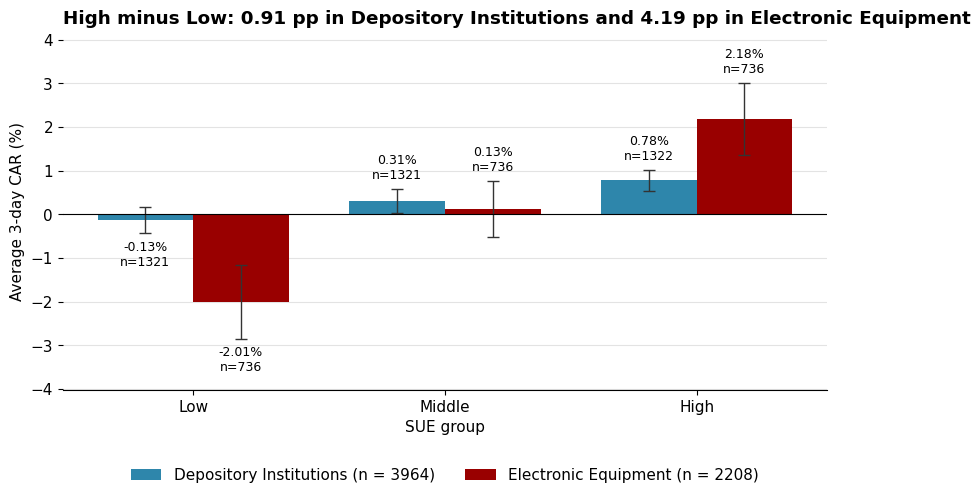

In [37]:
# ===== Figure 1: Average CAR by SUE group, both industries side by side =====
fig, ax = plt.subplots(figsize=(8.5, 5.2))
x = np.arange(len(LABELS))
width = 0.38

for j, (label_ind, df_ind, t_ind, col) in enumerate(INDUSTRIES):
    means = t_ind["mean"] * 100
    cis   = t_ind["ci95"] * 100
    ax.bar(x + (j - 0.5) * width, means, width, yerr=cis, capsize=4,
           color=col, label=f"{label_ind} (n = {len(df_ind)})",
           error_kw={"elinewidth": 1, "ecolor": "#333333"})
    for i, g in enumerate(LABELS):
        top = means.iloc[i] + cis.iloc[i] if means.iloc[i] >= 0 else means.iloc[i] - cis.iloc[i]
        ax.annotate(f"{means.iloc[i]:.2f}%\nn={t_ind.loc[g, 'n']}", (x[i] + (j - 0.5) * width, top),
                    xytext=(0, 5 if means.iloc[i] >= 0 else -5), textcoords="offset points",
                    ha="center", va="bottom" if means.iloc[i] >= 0 else "top", fontsize=9)

gaps = []
for _, df_ind, _, _ in INDUSTRIES:
    hi_g = df_ind.loc[df_ind["sue_group"] == "High", "car"].mean() * 100
    lo_g = df_ind.loc[df_ind["sue_group"] == "Low",  "car"].mean() * 100
    gaps.append(hi_g - lo_g)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, LABELS)
ax.set_title(f"High minus Low: {gaps[0]:.2f} pp in Depository Institutions and {gaps[1]:.2f} pp in Electronic Equipment",
             loc="left", fontweight="bold")
ax.set_xlabel("SUE group")
ax.set_ylabel("Average 3-day CAR (%)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.margins(y=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
fig.savefig("figure1_groups.png", dpi=200)
plt.show()

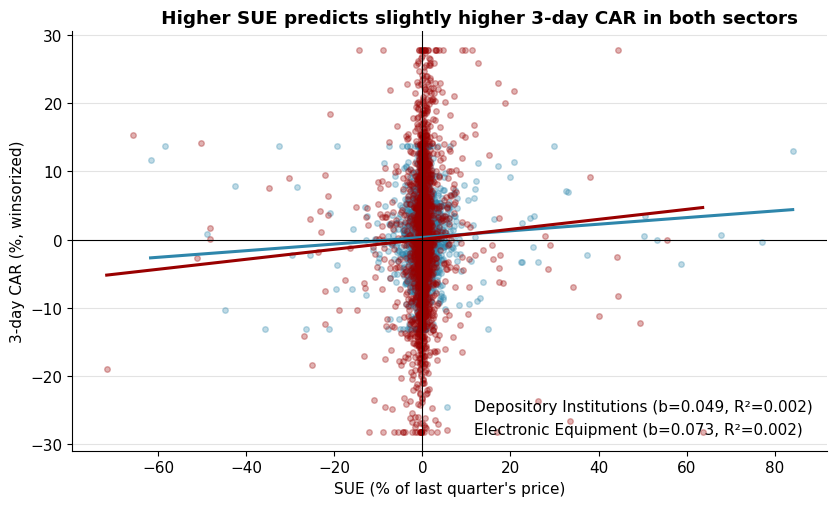

In [38]:
# ===== Figure 2: Scatter plot SUE vs CAR and regression line per industry =====
fig, ax = plt.subplots(figsize=(8.5, 5.2))

for label_ind, df_ind, _, col in INDUSTRIES:
    m_w = smf.ols("car_w ~ sue", data=df_ind).fit()
    ax.scatter(df_ind["sue"] * 100, df_ind["car_w"] * 100, s=16, alpha=0.30,
               color=col, label=f"{label_ind} (b={m_w.params['sue']:.3f}, R²={m_w.rsquared:.3f})")
    grid = pd.DataFrame({"sue": np.linspace(df_ind["sue"].min(), df_ind["sue"].max(), 100)})
    pred_y = m_w.predict(grid) * 100
    ax.plot(grid["sue"] * 100, pred_y, color=col, linewidth=2.2)

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("              Higher SUE predicts slightly higher 3-day CAR in both sectors",
             loc="left", fontweight="bold")
ax.set_xlabel("SUE (% of last quarter's price)")
ax.set_ylabel("3-day CAR (%, winsorized)")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
fig.savefig("figure2_regression.png", dpi=200)
plt.show()

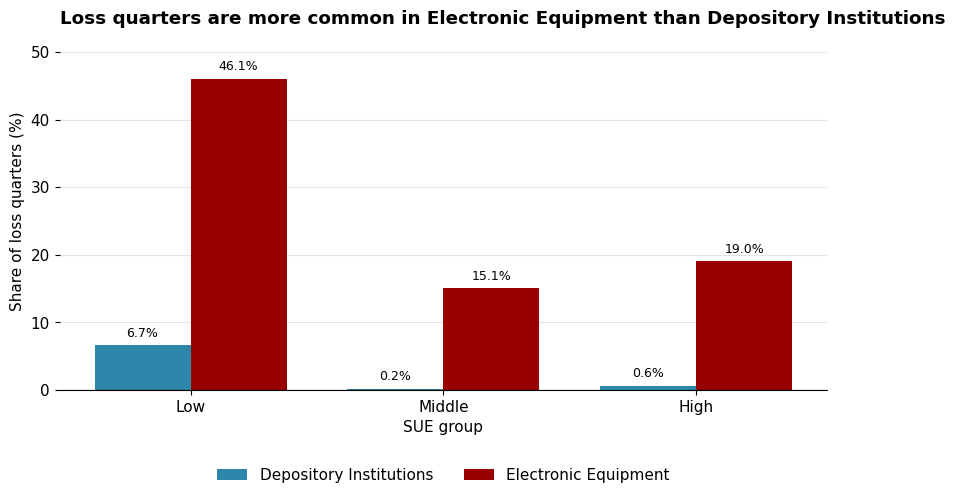

In [39]:
# ===== Figure 3: Why do they differ? Share of loss quarters (EPS < 0) by SUE group =====
fig, ax = plt.subplots(figsize=(8.5, 5.2))
x = np.arange(len(LABELS))
width = 0.38

for j, (label_ind, df_ind, _, col) in enumerate(INDUSTRIES):
    loss_pct = df_ind.groupby("sue_group", observed=False)["loss"].mean() * 100
    ax.bar(x + (j - 0.5) * width, loss_pct.values, width, color=col, label=label_ind)
    for i, g in enumerate(LABELS):
        val = loss_pct.loc[g]
        ax.annotate(f"{val:.1f}%", (x[i] + (j - 0.5) * width, val),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, LABELS)
ax.set_title("Loss quarters are more common in Electronic Equipment than Depository Institutions",
             loc="left", fontweight="bold")
ax.set_xlabel("SUE group")
ax.set_ylabel("Share of loss quarters (%)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.margins(y=0.15)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
fig.savefig("figure3_why_differ.png", dpi=200)
plt.show()